# Sub-etapa 1.3 · Implementación y entrenamiento de modelos: LSTM

**Objetivo de este notebook:** entrenar el tercer modelo del proyecto, una red neuronal **LSTM** (con dos capas convolucionales previas), y compararlo con Random Forest y XGBoost (notebook 03). A diferencia de esos modelos, la LSTM no recibe variables calculadas: recibe **directamente las señales del sensor**, cortadas en ventanas de pocos segundos, y aprende por sí misma qué patrones distinguen a quienes caen.

**Productos que genera:**

| Archivo | Contenido |
|---|---|
| `resultados/metricas_lstm_por_particion.csv` | Métricas de la LSTM en cada partición |
| `resultados/metricas_tres_modelos.csv` | Comparación de los tres modelos en las mismas particiones |
| `modelos/lstm.pt`, `modelos/info_lstm.json` | Modelo entrenado (checkpoint) y su información |
| `figuras/lstm_*.png` | Gráficos para el informe |

**Antes de ejecutarlo:** tiene que haberse ejecutado el notebook 01 (genera las señales limpias) y, para la comparación final, el notebook 03.

**Cómo ejecutarlo:** *Kernel → Restart Kernel and Run All Cells*. Tarda entre 15 y 30 minutos, porque la red se entrena 16 veces (15 de validación y el modelo final).

## 1. Configuración

Esta parte usa **PyTorch**, una librería para redes neuronales. Se instala una vez, en la terminal de Anaconda:

```
pip install torch
```

En Windows esto instala la versión para procesador (CPU), que es suficiente para este proyecto. Se eligió PyTorch y no TensorFlow porque TensorFlow todavía no tiene versión para Python 3.14.

In [1]:
import json
import platform
import time
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, confusion_matrix, f1_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from torch import nn

# --- Rutas ------------------------------------------------------------------
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESADOS = RAIZ / "datos" / "procesados"
SENALES = PROCESADOS / "senales_limpias"
MODELOS = RAIZ / "modelos"
RESULTADOS = RAIZ / "resultados"
FIGURAS = RAIZ / "figuras"
for carpeta in (MODELOS, RESULTADOS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# --- Datos de entrada ---------------------------------------------------------
FS_ORIGINAL = 100        # Hz, frecuencia de LTMM
DIEZMADO = 2             # se toma 1 de cada 2 muestras: 50 Hz (la señal ya está filtrada a 20 Hz)
VENTANA_S = 5.0          # largo de cada ventana (unos 9 pasos)
PASO_S = 2.5             # cada ventana empieza 2,5 s después de la anterior (se traslapan a la mitad)

# --- Red y entrenamiento -------------------------------------------------------
FILTROS = (16, 32)       # filtros de las dos capas convolucionales previas a la LSTM
TAMANO_OCULTO = 32       # neuronas de la LSTM: pocas, porque hay pocos datos
DROPOUT = 0.3            # apaga al azar el 30 % de las conexiones al entrenar, para no memorizar
TASA_APRENDIZAJE = 1e-3
TAMANO_LOTE = 32
EPOCAS_MAX = 100
EPOCAS_MIN = 40          # entrena al menos 40 épocas antes de evaluar si conviene parar
PACIENCIA = 20           # después, se detiene si la pérdida de validación no mejora en 20 épocas
FRACCION_VALIDACION = 0.2  # personas del entrenamiento que se separan para decidir cuándo parar

# --- Validación (igual que el notebook 03) -----------------------------------
SEMILLA = 42
N_PARTICIONES = 5
N_REPETICIONES = 3       # 15 entrenamientos (la red es más lenta que los árboles)

torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"torch {torch.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

Python 3.14.6 | numpy 2.4.6 | pandas 3.0.3 | torch 2.14.1+cpu | scikit-learn 1.9.0 | matplotlib 3.11.0


## 2. Datos: de señales a ventanas

Se usan las mismas 72 personas de `labwalks_modelo.csv` (la etiqueta sale de ahí) y sus señales limpias de la sub-etapa 1.2: los seis canales, ya recortados y filtrados.

Una LSTM necesita muchos ejemplos, y aquí hay solo 72 personas. Por eso cada caminata se corta en **ventanas de 5 s que se traslapan a la mitad**: de una caminata de 40 s salen unas 15 ventanas, y la red se entrena con todas. Cada ventana lleva la etiqueta de su persona.

Para que la comparación sea justa, al final se vuelve al nivel de **persona**: la probabilidad de caer de una persona es el promedio de las probabilidades de sus ventanas. Así las métricas son comparables con las del notebook 03.

In [2]:
tabla = pd.read_csv(PROCESADOS / "labwalks_modelo.csv")
registros = tabla["registro"].tolist()
y = tabla["cae"].to_numpy().astype(int)

largo = int(VENTANA_S * FS_ORIGINAL / DIEZMADO)
avance = int(PASO_S * FS_ORIGINAL / DIEZMADO)


def ventanas_de(registro):
    senal = pd.read_csv(SENALES / f"{registro}.csv").drop(columns="tiempo_s")
    x = senal.to_numpy(dtype=np.float32)[::DIEZMADO]
    inicios = range(0, len(x) - largo + 1, avance)
    return np.stack([x[i:i + largo] for i in inicios]), list(senal.columns)


faltan = [r for r in registros if not (SENALES / f"{r}.csv").exists()]
assert not faltan, f"Faltan señales limpias de: {faltan}. Ejecuta primero el notebook 01."
VENTANAS, CANALES = {}, None
for r in registros:
    VENTANAS[r], CANALES = ventanas_de(r)

n_ventanas = pd.Series({r: len(v) for r, v in VENTANAS.items()})
print(f"Personas: {len(registros)} ({y.sum()} caen, {(y == 0).sum()} no caen)")
print(f"Canales ({len(CANALES)}): {', '.join(CANALES)}")
print(f"Cada ventana: {largo} muestras ({VENTANA_S:g} s a {FS_ORIGINAL // DIEZMADO} Hz) × {len(CANALES)} canales")
print(f"Ventanas por persona: mínimo {n_ventanas.min()}, mediana {int(n_ventanas.median())}, máximo {n_ventanas.max()} "
      f"| total {n_ventanas.sum()}")

Personas: 72 (34 caen, 38 no caen)
Canales (6): acc_v, acc_ml, acc_ap, giro_yaw, giro_pitch, giro_roll
Cada ventana: 250 muestras (5 s a 50 Hz) × 6 canales
Ventanas por persona: mínimo 8, mediana 15, máximo 44 | total 1150


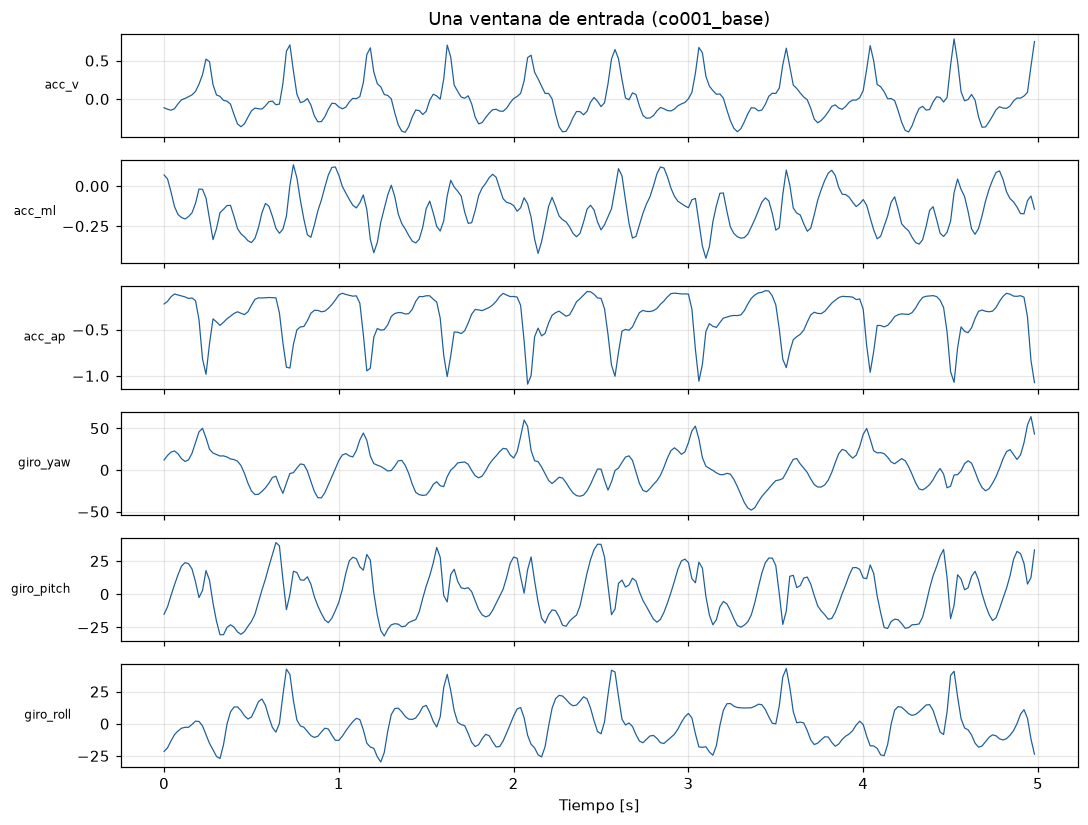

In [3]:
# Así ve la red una ventana: 5 s de los seis canales
ejemplo = VENTANAS[registros[0]][0]
t = np.arange(largo) / (FS_ORIGINAL / DIEZMADO)
fig, ejes = plt.subplots(len(CANALES), 1, figsize=(10, 1.1 * len(CANALES) + 1), sharex=True)
for i, (eje, canal) in enumerate(zip(ejes, CANALES)):
    eje.plot(t, ejemplo[:, i], lw=0.8, color="#1f5f99")
    eje.set_ylabel(canal, rotation=0, ha="right", va="center", fontsize=8)
ejes[0].set_title(f"Una ventana de entrada ({registros[0]})")
ejes[-1].set_xlabel("Tiempo [s]")
fig.tight_layout()
fig.savefig(FIGURAS / "lstm_ventana_ejemplo.png", dpi=150)

## 3. La red

La red tiene tres partes:

1. **Dos capas convolucionales** recorren la señal con filtros cortos (5 muestras, 0,1 s) y detectan patrones locales, como el impacto del talón. Además reducen la ventana de 250 a 63 pasos de tiempo.
2. **La LSTM** lee esa secuencia paso a paso y guarda una memoria de lo que ha visto (por eso sirve para señales en el tiempo). Al terminar la ventana, su estado final resume la caminata.
3. **Dos capas simples** convierten ese resumen en un solo número: la probabilidad de que la persona caiga.

```
ventana (250 × 6) → convolución (16) → convolución (32) → LSTM (32) → Dropout → capa de 16 → probabilidad
```

**Por qué las capas convolucionales.** En las pruebas previas, una LSTM sola sobre las 250 muestras crudas no lograba aprender: su pérdida de validación no bajaba. Con las convoluciones delante, la LSTM recibe una secuencia más corta y con patrones ya destacados, y aprende sin problemas. Esta combinación (CNN + LSTM) es la que usaron Kiprijanovska et al. (2020) y Alqurashi et al. (2026) en la literatura revisada.

La red es pequeña a propósito: con pocas personas, una red grande memoriza los ejemplos de entrenamiento y falla con personas nuevas.

In [4]:
class RedLSTM(nn.Module):
    def __init__(self, n_canales, oculto=TAMANO_OCULTO, dropout=DROPOUT, filtros=FILTROS):
        super().__init__()
        self.convoluciones = nn.Sequential(
            nn.Conv1d(n_canales, filtros[0], kernel_size=5, stride=2, padding=2), nn.ReLU(),
            nn.Conv1d(filtros[0], filtros[1], kernel_size=5, stride=2, padding=2), nn.ReLU(),
        )
        self.lstm = nn.LSTM(input_size=filtros[1], hidden_size=oculto, batch_first=True)
        self.cabeza = nn.Sequential(nn.Dropout(dropout), nn.Linear(oculto, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, x):                      # x: (ventanas, tiempo, canales)
        z = self.convoluciones(x.transpose(1, 2)).transpose(1, 2)   # las convoluciones esperan (ventanas, canales, tiempo)
        _, (h, _) = self.lstm(z)               # h: estado final de la LSTM = resumen de la ventana
        return self.cabeza(h[-1]).squeeze(-1)  # un valor por ventana (antes de convertirlo en probabilidad)


red = RedLSTM(len(CANALES))
print(red)
print(f"Parámetros entrenables: {sum(p.numel() for p in red.parameters()):,}".replace(",", "."))

RedLSTM(
  (convoluciones): Sequential(
    (0): Conv1d(6, 16, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): ReLU()
    (2): Conv1d(16, 32, kernel_size=(5,), stride=(2,), padding=(2,))
    (3): ReLU()
  )
  (lstm): LSTM(32, 32, batch_first=True)
  (cabeza): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=32, out_features=16, bias=True)
    (2): ReLU()
    (3): Linear(in_features=16, out_features=1, bias=True)
  )
)
Parámetros entrenables: 12.081


## 4. Entrenamiento

Para cada partición:

1. **Separar por persona.** Las personas de prueba no se usan para nada durante el entrenamiento. Además, del grupo de entrenamiento se aparta un 20 % de personas como *validación*, que sirve para decidir cuándo parar.
2. **Normalizar.** Cada canal se lleva a promedio 0 y desviación 1, usando **solo** los datos de entrenamiento.
3. **Entrenar por épocas.** En cada época la red ve todas las ventanas de entrenamiento. Se mide la pérdida (el error) en validación y se guarda la mejor versión. Después de 40 épocas, si la validación no mejora en 20 épocas seguidas, se detiene (*early stopping*), lo que evita que siga memorizando. El mínimo de 40 épocas es necesario porque, al principio, la pérdida de validación puede ser baja solo porque la red todavía responde lo mismo para todos; si se permite parar antes, a veces se queda con esa versión que no aprendió nada. Además se limita el tamaño de cada ajuste (*gradient clipping*), que estabiliza el entrenamiento de las LSTM.
4. **Predecir por persona.** La probabilidad de cada persona de prueba es el promedio de sus ventanas.

Todas las ventanas de una persona quedan siempre del mismo lado: nunca hay ventanas de una misma persona en entrenamiento y en prueba, que sería una fuga de datos.

In [5]:
def apilar(personas):
    X = np.concatenate([VENTANAS[registros[i]] for i in personas])
    Y = np.concatenate([np.full(len(VENTANAS[registros[i]]), y[i], dtype=np.float32) for i in personas])
    return X, Y


def entrenar(personas, semilla):
    # Entrena una red con estas personas; devuelve la red, la normalización y la historia de pérdidas
    torch.manual_seed(semilla)
    ent, val = train_test_split(personas, test_size=FRACCION_VALIDACION, stratify=y[personas], random_state=semilla)
    X_ent, Y_ent = apilar(ent)
    X_val, Y_val = apilar(val)
    media, desv = X_ent.mean(axis=(0, 1)), X_ent.std(axis=(0, 1)) + 1e-6
    X_ent, X_val = (X_ent - media) / desv, (X_val - media) / desv
    X_ent, Y_ent, X_val, Y_val = map(torch.from_numpy, (X_ent, Y_ent, X_val, Y_val))

    red = RedLSTM(X_ent.shape[2])
    optimizador = torch.optim.Adam(red.parameters(), lr=TASA_APRENDIZAJE)
    perdida = nn.BCEWithLogitsLoss()
    generador = torch.Generator().manual_seed(semilla)

    historia, mejor, mejor_estado, sin_mejora = [], np.inf, None, 0
    for epoca in range(EPOCAS_MAX):
        red.train()
        orden = torch.randperm(len(X_ent), generator=generador)
        total = 0.0
        for i in range(0, len(orden), TAMANO_LOTE):
            lote = orden[i:i + TAMANO_LOTE]
            optimizador.zero_grad()
            error = perdida(red(X_ent[lote]), Y_ent[lote])
            error.backward()
            nn.utils.clip_grad_norm_(red.parameters(), max_norm=1.0)   # evita ajustes demasiado grandes
            optimizador.step()
            total += error.item() * len(lote)
        red.eval()
        with torch.no_grad():
            error_val = perdida(red(X_val), Y_val).item()
        historia.append({"epoca": epoca + 1, "entrenamiento": total / len(X_ent), "validacion": error_val})
        if error_val < mejor - 1e-4:
            mejor, sin_mejora = error_val, 0
            mejor_estado = {k: v.clone() for k, v in red.state_dict().items()}
        else:
            sin_mejora += 1
            if epoca + 1 >= EPOCAS_MIN and sin_mejora >= PACIENCIA:
                break
    red.load_state_dict(mejor_estado)
    red.eval()
    return red, (media, desv), pd.DataFrame(historia)


def probabilidad_personas(red, normalizacion, personas):
    media, desv = normalizacion
    with torch.no_grad():
        return np.array([torch.sigmoid(red(torch.from_numpy((VENTANAS[registros[i]] - media) / desv))).mean().item()
                         for i in personas])


def metricas(y_real, prob):
    pred = (prob >= 0.5).astype(int)
    return {"exactitud": accuracy_score(y_real, pred), "sensibilidad": recall_score(y_real, pred, zero_division=0),
            "especificidad": recall_score(y_real, pred, pos_label=0, zero_division=0),
            "f1": f1_score(y_real, pred, zero_division=0), "auc": roc_auc_score(y_real, prob)}

### 4.1 Validación cruzada

Se usan **exactamente las mismas particiones** que en el notebook 03 (misma semilla y mismo orden de personas), así que las primeras 15 pruebas de Random Forest y XGBoost se pueden comparar una a una con las de la LSTM.

In [6]:
validacion = RepeatedStratifiedKFold(n_splits=N_PARTICIONES, n_repeats=N_REPETICIONES, random_state=SEMILLA)
filas, historias = [], []
prob_primera_vuelta = np.full(len(y), np.nan)
inicio = time.time()
for k, (ent, prueba) in enumerate(validacion.split(np.zeros(len(y)), y)):
    red, normalizacion, historia = entrenar(ent, semilla=SEMILLA + k)
    prob = probabilidad_personas(red, normalizacion, prueba)
    filas.append({"particion": k + 1, "epocas": len(historia), **metricas(y[prueba], prob)})
    historias.append(historia.assign(particion=k + 1))
    if k < N_PARTICIONES:
        prob_primera_vuelta[prueba] = prob
    print(f"Partición {k + 1:2d}/{N_PARTICIONES * N_REPETICIONES}: AUC {filas[-1]['auc']:.2f} | "
          f"sensibilidad {filas[-1]['sensibilidad']:.2f} | {len(historia)} épocas | {time.time() - inicio:.0f} s")

lstm_particiones = pd.DataFrame(filas)
lstm_particiones.insert(0, "modelo", "LSTM")
lstm_particiones.to_csv(RESULTADOS / "metricas_lstm_por_particion.csv", index=False)
lstm_particiones[["exactitud", "sensibilidad", "especificidad", "f1", "auc", "epocas"]].describe().loc[["mean", "std"]].round(3)

Partición  1/15: AUC 0.75 | sensibilidad 1.00 | 40 épocas | 8 s
Partición  2/15: AUC 0.68 | sensibilidad 0.57 | 40 épocas | 16 s
Partición  3/15: AUC 0.58 | sensibilidad 0.50 | 40 épocas | 25 s
Partición  4/15: AUC 0.37 | sensibilidad 0.43 | 40 épocas | 34 s
Partición  5/15: AUC 0.73 | sensibilidad 0.14 | 40 épocas | 42 s
Partición  6/15: AUC 0.32 | sensibilidad 0.86 | 40 épocas | 51 s
Partición  7/15: AUC 0.59 | sensibilidad 0.00 | 40 épocas | 60 s
Partición  8/15: AUC 0.29 | sensibilidad 0.83 | 40 épocas | 68 s
Partición  9/15: AUC 0.45 | sensibilidad 0.86 | 40 épocas | 75 s
Partición 10/15: AUC 0.53 | sensibilidad 0.86 | 40 épocas | 84 s
Partición 11/15: AUC 0.64 | sensibilidad 0.71 | 40 épocas | 93 s
Partición 12/15: AUC 0.71 | sensibilidad 1.00 | 40 épocas | 101 s
Partición 13/15: AUC 0.56 | sensibilidad 0.00 | 40 épocas | 110 s
Partición 14/15: AUC 0.59 | sensibilidad 0.86 | 40 épocas | 120 s
Partición 15/15: AUC 0.49 | sensibilidad 0.14 | 40 épocas | 128 s


,exactitud,sensibilidad,especificidad,f1,auc,epocas
mean,0.532,0.584,0.482,0.472,0.553,40.0
std,0.069,0.361,0.379,0.236,0.146,0.0


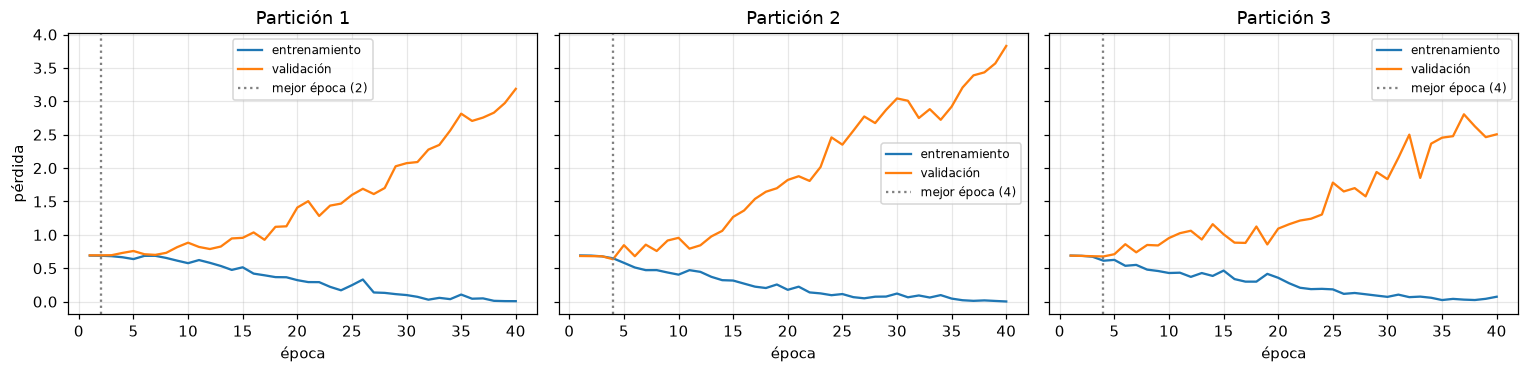

In [7]:
# Curvas de aprendizaje: si la pérdida de validación sube mientras la de entrenamiento baja, la red está memorizando
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for eje, h in zip(ejes, historias[:3]):
    eje.plot(h["epoca"], h["entrenamiento"], label="entrenamiento")
    eje.plot(h["epoca"], h["validacion"], label="validación")
    mejor = h.loc[h["validacion"].idxmin(), "epoca"]
    eje.axvline(mejor, color="gray", ls=":", label=f"mejor época ({mejor})")
    eje.set(title=f"Partición {h['particion'].iloc[0]}", xlabel="época")
    eje.legend(fontsize=8)
ejes[0].set_ylabel("pérdida")
fig.tight_layout()
fig.savefig(FIGURAS / "lstm_curvas_aprendizaje.png", dpi=150)

## 5. Comparación de los tres modelos

Se juntan los resultados de la LSTM con los del notebook 03, tomando de ese notebook **solo las particiones que coinciden** con estas.

In [8]:
METRICAS = ["exactitud", "sensibilidad", "especificidad", "f1", "auc"]
archivo_03 = RESULTADOS / "metricas_por_particion.csv"
if archivo_03.exists():
    anteriores = pd.read_csv(archivo_03)
    anteriores["particion"] = anteriores.groupby("modelo").cumcount() + 1
    anteriores = anteriores[anteriores["particion"] <= N_PARTICIONES * N_REPETICIONES]
    todos = pd.concat([anteriores, lstm_particiones.drop(columns="epocas")], ignore_index=True)
else:
    print("No se encontró el resultado del notebook 03; se muestra solo la LSTM.")
    todos = lstm_particiones.drop(columns="epocas")

orden = list(dict.fromkeys(todos["modelo"]))
resumen = todos.groupby("modelo")[METRICAS].agg(["mean", "std"]).reindex(orden)
tabla_final = pd.DataFrame({m: [f"{resumen.loc[i, (m, 'mean')]:.3f} ± {resumen.loc[i, (m, 'std')]:.3f}" for i in orden]
                            for m in METRICAS}, index=orden)
resumen.columns = [f"{m}_{e}" for m, e in resumen.columns]
resumen.to_csv(RESULTADOS / "metricas_tres_modelos.csv")
print(f"Promedio de {N_PARTICIONES * N_REPETICIONES} pruebas, en las mismas particiones para todos los modelos:")
tabla_final

Promedio de 15 pruebas, en las mismas particiones para todos los modelos:


,exactitud,sensibilidad,especificidad,f1,auc
Sin modelo,0.528 ± 0.027,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Solo frec_dominante_hz,0.708 ± 0.129,0.597 ± 0.235,0.805 ± 0.103,0.641 ± 0.189,0.749 ± 0.149
Solo TUG,0.557 ± 0.117,0.394 ± 0.174,0.700 ± 0.222,0.446 ± 0.147,0.658 ± 0.132
Random Forest,0.644 ± 0.110,0.637 ± 0.174,0.646 ± 0.162,0.624 ± 0.116,0.682 ± 0.139
XGBoost,0.602 ± 0.104,0.576 ± 0.228,0.618 ± 0.187,0.559 ± 0.165,0.669 ± 0.129
LSTM,0.532 ± 0.069,0.584 ± 0.361,0.482 ± 0.379,0.472 ± 0.236,0.553 ± 0.146


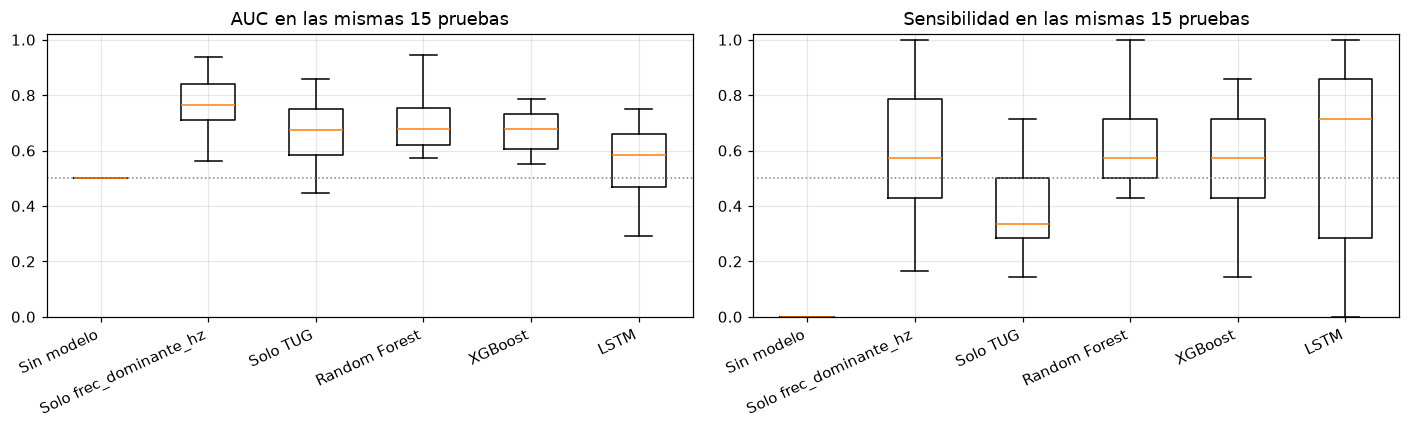

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for eje, metrica in zip(ejes, ["auc", "sensibilidad"]):
    datos_m = [todos.loc[todos["modelo"] == m, metrica] for m in orden]
    eje.boxplot(datos_m, widths=0.5, showfliers=False)
    eje.set_xticks(range(1, len(orden) + 1), orden, rotation=25, ha="right")
    eje.axhline(0.5, color="gray", ls=":", lw=1)
    eje.set(title=f"{'AUC' if metrica == 'auc' else metrica.capitalize()} en las mismas {N_PARTICIONES * N_REPETICIONES} pruebas",
            ylim=(0, 1.02))
fig.tight_layout()
fig.savefig(FIGURAS / "lstm_comparacion_modelos.png", dpi=150)

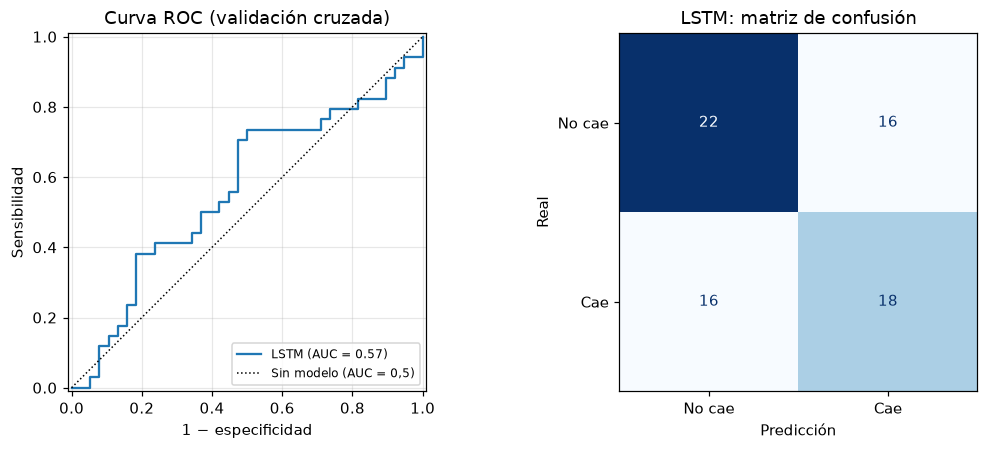

In [10]:
# Curva ROC y matriz de confusión de la LSTM (primera repetición: cada persona predicha una vez, por una red que no la vio)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2))
RocCurveDisplay.from_predictions(y, prob_primera_vuelta, name="LSTM", ax=ejes[0])
ejes[0].plot([0, 1], [0, 1], "k:", lw=1, label="Sin modelo (AUC = 0,5)")
ejes[0].set(title="Curva ROC (validación cruzada)", xlabel="1 − especificidad", ylabel="Sensibilidad")
ejes[0].legend(loc="lower right", fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(y, (prob_primera_vuelta >= 0.5).astype(int)),
                       display_labels=["No cae", "Cae"]).plot(ax=ejes[1], colorbar=False, cmap="Blues")
ejes[1].set(title="LSTM: matriz de confusión", xlabel="Predicción", ylabel="Real")
ejes[1].grid(False)
fig.tight_layout()
fig.savefig(FIGURAS / "lstm_roc_confusion.png", dpi=150)

## 6. Modelo final y checkpoint

Se entrena una última red con todas las personas (apartando igualmente un 20 % para decidir cuándo parar) y se guarda junto con todo lo necesario para usarla después: la normalización de cada canal, el orden de los canales y el formato de las ventanas.

In [11]:
red_final, (media, desv), historia_final = entrenar(np.arange(len(y)), semilla=SEMILLA)
torch.save(red_final.state_dict(), MODELOS / "lstm.pt")
info = {
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "datos": "datos/procesados/senales_limpias/*.csv (personas de labwalks_modelo.csv)",
    "personas": int(len(y)),
    "canales_en_orden": CANALES,
    "entrada": {"frecuencia_hz": FS_ORIGINAL // DIEZMADO, "diezmado_desde_100_hz": DIEZMADO,
                "ventana_s": VENTANA_S, "paso_s": PASO_S, "muestras_por_ventana": largo},
    "normalizacion": {"media": media.round(6).tolist(), "desviacion": desv.round(6).tolist()},
    "red": {"tipo": "CNN + LSTM", "filtros_convolucion": list(FILTROS), "tamano_oculto": TAMANO_OCULTO, "dropout": DROPOUT, "tasa_aprendizaje": TASA_APRENDIZAJE,
            "tamano_lote": TAMANO_LOTE, "epocas_entrenadas": int(len(historia_final))},
    "prediccion_persona": "promedio de la probabilidad de sus ventanas; umbral 0,5",
    "validacion": f"{N_PARTICIONES} particiones estratificadas x {N_REPETICIONES} repeticiones, semilla {SEMILLA}",
    "metricas_validacion": {m: round(float(lstm_particiones[m].mean()), 4) for m in METRICAS},
    "versiones": {"python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__},
}
(MODELOS / "info_lstm.json").write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Guardado: modelos/lstm.pt y modelos/info_lstm.json ({len(historia_final)} épocas)")

Guardado: modelos/lstm.pt y modelos/info_lstm.json (40 épocas)


In [12]:
# Prueba: cargar el checkpoint y predecir, como se hará en la Etapa 2
info_cargada = json.loads((MODELOS / "info_lstm.json").read_text(encoding="utf-8"))
cargada = RedLSTM(len(info_cargada["canales_en_orden"]), info_cargada["red"]["tamano_oculto"])
cargada.load_state_dict(torch.load(MODELOS / "lstm.pt"))
cargada.eval()
norm = (np.array(info_cargada["normalizacion"]["media"], dtype=np.float32),
        np.array(info_cargada["normalizacion"]["desviacion"], dtype=np.float32))
muestra = np.random.default_rng(SEMILLA).choice(len(y), 3, replace=False)
pd.DataFrame({"registro": [registros[i] for i in muestra], "grupo real": tabla["grupo"].iloc[muestra].to_list(),
              "probabilidad de caer": probabilidad_personas(cargada, norm, muestra).round(2)})

,registro,grupo real,probabilidad de caer
0,fl011_base,Cae,0.62
1,co007_base,No cae,0.13
2,fl021_base,Cae,0.61


## 7. Resumen para el informe

In [13]:
f = lambda m, c: f"{resumen.loc[m, c + '_mean']:.2f} ± {resumen.loc[m, c + '_std']:.2f}".replace(".", ",")
print(f"* Entrada: {len(registros)} personas, {n_ventanas.sum()} ventanas de {VENTANA_S:g} s "
      f"({largo} muestras a {FS_ORIGINAL // DIEZMADO} Hz) con {len(CANALES)} canales, traslapadas al 50 %.")
print(f"* Red: dos convoluciones ({FILTROS[0]} y {FILTROS[1]} filtros) + LSTM de {TAMANO_OCULTO} unidades + capa de 16, dropout {DROPOUT}, parada temprana "
      f"(entre {lstm_particiones['epocas'].min()} y {lstm_particiones['epocas'].max()} épocas).")
print(f"* Validación: {N_PARTICIONES} particiones x {N_REPETICIONES} repeticiones por persona, "
      f"mismas particiones que Random Forest y XGBoost.")
for m in orden:
    print(f"* {m}: exactitud {f(m, 'exactitud')}, sensibilidad {f(m, 'sensibilidad')}, "
          f"especificidad {f(m, 'especificidad')}, F1 {f(m, 'f1')}, AUC {f(m, 'auc')}")

* Entrada: 72 personas, 1150 ventanas de 5 s (250 muestras a 50 Hz) con 6 canales, traslapadas al 50 %.
* Red: dos convoluciones (16 y 32 filtros) + LSTM de 32 unidades + capa de 16, dropout 0.3, parada temprana (entre 40 y 40 épocas).
* Validación: 5 particiones x 3 repeticiones por persona, mismas particiones que Random Forest y XGBoost.
* Sin modelo: exactitud 0,53 ± 0,03, sensibilidad 0,00 ± 0,00, especificidad 1,00 ± 0,00, F1 0,00 ± 0,00, AUC 0,50 ± 0,00
* Solo frec_dominante_hz: exactitud 0,71 ± 0,13, sensibilidad 0,60 ± 0,23, especificidad 0,80 ± 0,10, F1 0,64 ± 0,19, AUC 0,75 ± 0,15
* Solo TUG: exactitud 0,56 ± 0,12, sensibilidad 0,39 ± 0,17, especificidad 0,70 ± 0,22, F1 0,45 ± 0,15, AUC 0,66 ± 0,13
* Random Forest: exactitud 0,64 ± 0,11, sensibilidad 0,64 ± 0,17, especificidad 0,65 ± 0,16, F1 0,62 ± 0,12, AUC 0,68 ± 0,14
* XGBoost: exactitud 0,60 ± 0,10, sensibilidad 0,58 ± 0,23, especificidad 0,62 ± 0,19, F1 0,56 ± 0,17, AUC 0,67 ± 0,13
* LSTM: exactitud 0,53 ± 0,07, sensibi

**Interpretación**

* La LSTM (con dos capas convolucionales previas) no superó a los otros modelos: AUC 0,55 ± 0,15, cerca del azar, frente a 0,68 de Random Forest, 0,67 de XGBoost y 0,75 de la regresión con solo la frecuencia dominante (en las mismas 15 particiones).
* Las curvas de aprendizaje muestran sobreajuste: la pérdida de entrenamiento baja casi a 0, mientras la de validación sube desde las primeras épocas. La red aprende a reconocer a las personas de entrenamiento, no un patrón de marcha que sirva para personas nuevas.
* Aunque las ventanas dan 1.150 ejemplos, provienen de solo 72 personas; para una red neuronal, la cantidad efectiva de ejemplos independientes es la de personas.
* En esta muestra, el desempeño empeora a medida que aumenta la complejidad del modelo, lo que concuerda con el riesgo de sobreajuste en estudios con menos de 100 participantes señalado en la literatura.
* **Siguiente paso (1.4):** comparación formal de los modelos; para la LSTM se podría probar una red más pequeña y más regularizada, aunque con esta cantidad de personas es poco probable que supere a los modelos simples.